## 1. Config

In [1]:
from __future__ import annotations

import csv
import hashlib
import json
import re
from collections import Counter, defaultdict
from pathlib import Path

# --- edit ------------------------------------------------------------------
ROOT = "/kaggle/input/datasets/atkiyaanisa/acne04/acne04"
OUT = "fold_audit_out"
LABEL_HINT = "Classification"   # prefer images under this directory, if present
# ---------------------------------------------------------------------------

## 2. Helpers

In [2]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
GRADE_RE = re.compile(r"levle(\d+)_", re.I)


def grade_of(name):
    m = GRADE_RE.match(Path(name).name)
    return int(m.group(1)) if m else None


def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as fh:
        while True:
            b = fh.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def pixel_md5(path):
    """Hash the decoded pixels, so a re-encode of the same photo still matches."""
    try:
        from PIL import Image
        with Image.open(path) as im:
            im = im.convert("RGB")
            return hashlib.md5(im.tobytes()).hexdigest(), im.size
    except Exception:
        return None, None

## 3. Run

In [3]:
def main():
    root, out = Path(ROOT), Path(OUT)
    out.mkdir(parents=True, exist_ok=True)

    # one path per filename, preferring the classification copy
    chosen = {}
    for p in root.rglob("*"):
        if p.suffix.lower() not in IMAGE_EXTS or not p.is_file():
            continue
        prev = chosen.get(p.name)
        if prev is None or (LABEL_HINT in p.parts and LABEL_HINT not in prev.parts):
            chosen[p.name] = p
    names = sorted(chosen)
    print("=" * 74)
    print(f"DUPLICATE VERIFICATION   {len(names)} images")
    print("=" * 74)

    fmd5, pmd5, sizes = {}, {}, {}
    for i, n in enumerate(names, 1):
        p = chosen[n]
        fmd5[n] = file_md5(p)
        h, sz = pixel_md5(p)
        pmd5[n], sizes[n] = h, sz
        if i % 250 == 0:
            print(f"  hashed {i}/{len(names)}", end="\r")
    print(f"  hashed {len(names)}/{len(names)}")

    def report(label, table):
        buckets = defaultdict(list)
        for n, h in table.items():
            if h:
                buckets[h].append(n)
        groups = [sorted(v) for v in buckets.values() if len(v) > 1]
        n_imgs = sum(len(g) for g in groups)
        print(f"\n{'-' * 74}\n{label}\n{'-' * 74}")
        print(f"  duplicate groups : {len(groups)}")
        print(f"  images involved  : {n_imgs}")
        print(f"  distinct images  : {len(names) - n_imgs + len(groups)}")

        cross = [g for g in groups
                 if len({grade_of(x) for x in g if grade_of(x) is not None}) > 1]
        print(f"  groups spanning MORE THAN ONE grade: {len(cross)}")
        for g in cross:
            print("    " + "   ".join(f"{x} (grade {grade_of(x)})" for x in g))
        return groups, cross

    fgroups, fcross = report("A. identical FILE bytes  (strongest evidence)", fmd5)
    pgroups, pcross = report("B. identical decoded PIXELS  (catches re-encodes)", pmd5)

    print("\n" + "=" * 74)
    print("READING")
    print("=" * 74)
    if fcross or pcross:
        n = len(fcross) if fcross else len(pcross)
        kind = "byte-identical" if fcross else "pixel-identical"
        print(f"  {n} {kind} group(s) carry more than one severity grade.")
        print("  Because the grade is exactly rule(lesion count), the same photograph")
        print("  has two different lesion counts recorded. The dataset contradicts")
        print("  itself in its own terms. This is checkable by anyone in seconds.")
    elif fgroups or pgroups:
        print("  Duplicates exist but none spans two grades: a redundancy, not a")
        print("  contradiction. Still worth one sentence, since duplicates inflate")
        print("  any random split.")
    else:
        print("  No exact duplicates by either hash. The cosine-1.0 pairs are then")
        print("  near-identical rather than identical - report them as such, or not")
        print("  at all. Do not claim duplication without this confirmation.")

    rows = []
    for g in (fgroups or pgroups):
        for x in g:
            rows.append({"group": g[0], "image": x, "grade": grade_of(x),
                         "size": sizes.get(x), "file_md5": fmd5.get(x),
                         "pixel_md5": pmd5.get(x)})
    with (out / "duplicate_groups.csv").open("w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=["group", "image", "grade", "size",
                                           "file_md5", "pixel_md5"])
        w.writeheader()
        w.writerows(rows)

    (out / "duplicate_verification.json").write_text(json.dumps({
        "n_images": len(names),
        "file_md5_groups": fgroups, "file_md5_cross_grade": fcross,
        "pixel_md5_groups": pgroups, "pixel_md5_cross_grade": pcross,
    }, indent=2))
    print(f"\n  wrote {out/'duplicate_groups.csv'}, {out/'duplicate_verification.json'}")

    # render the cross-grade groups for visual confirmation
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        from PIL import Image
        show = fcross or pcross
        if show:
            k = min(len(show), 12)
            wmax = max(len(g) for g in show[:k])
            fig, axes = plt.subplots(k, wmax, figsize=(3 * wmax, 2.6 * k),
                                     squeeze=False)
            for i, g in enumerate(show[:k]):
                for j in range(wmax):
                    ax = axes[i][j]
                    ax.axis("off")
                    if j < len(g):
                        ax.imshow(Image.open(chosen[g[j]]).convert("RGB"))
                        ax.set_title(f"{g[j]}\ngrade {grade_of(g[j])}", fontsize=7)
            plt.tight_layout()
            fig.savefig(out / "cross_grade_duplicates.png", dpi=90)
            print(f"  wrote {out/'cross_grade_duplicates.png'} - confirm by eye")
    except Exception as e:
        print(f"  (rendering skipped: {e})")
    return 0

_ = main()

DUPLICATE VERIFICATION   1457 images
  hashed 1457/1457

--------------------------------------------------------------------------
A. identical FILE bytes  (strongest evidence)
--------------------------------------------------------------------------
  duplicate groups : 38
  images involved  : 76
  distinct images  : 1419
  groups spanning MORE THAN ONE grade: 9
    levle0_120.jpg (grade 0)   levle1_486.jpg (grade 1)
    levle0_121.jpg (grade 0)   levle1_504.jpg (grade 1)
    levle0_172.jpg (grade 0)   levle1_283.jpg (grade 1)
    levle0_185.jpg (grade 0)   levle1_286.jpg (grade 1)
    levle1_131.jpg (grade 1)   levle2_128.jpg (grade 2)
    levle1_16.jpg (grade 1)   levle2_150.jpg (grade 2)
    levle1_20.jpg (grade 1)   levle2_151.jpg (grade 2)
    levle1_22.jpg (grade 1)   levle2_152.jpg (grade 2)
    levle1_23.jpg (grade 1)   levle2_153.jpg (grade 2)

--------------------------------------------------------------------------
B. identical decoded PIXELS  (catches re-encodes)
------

## 4. Look at the duplicates



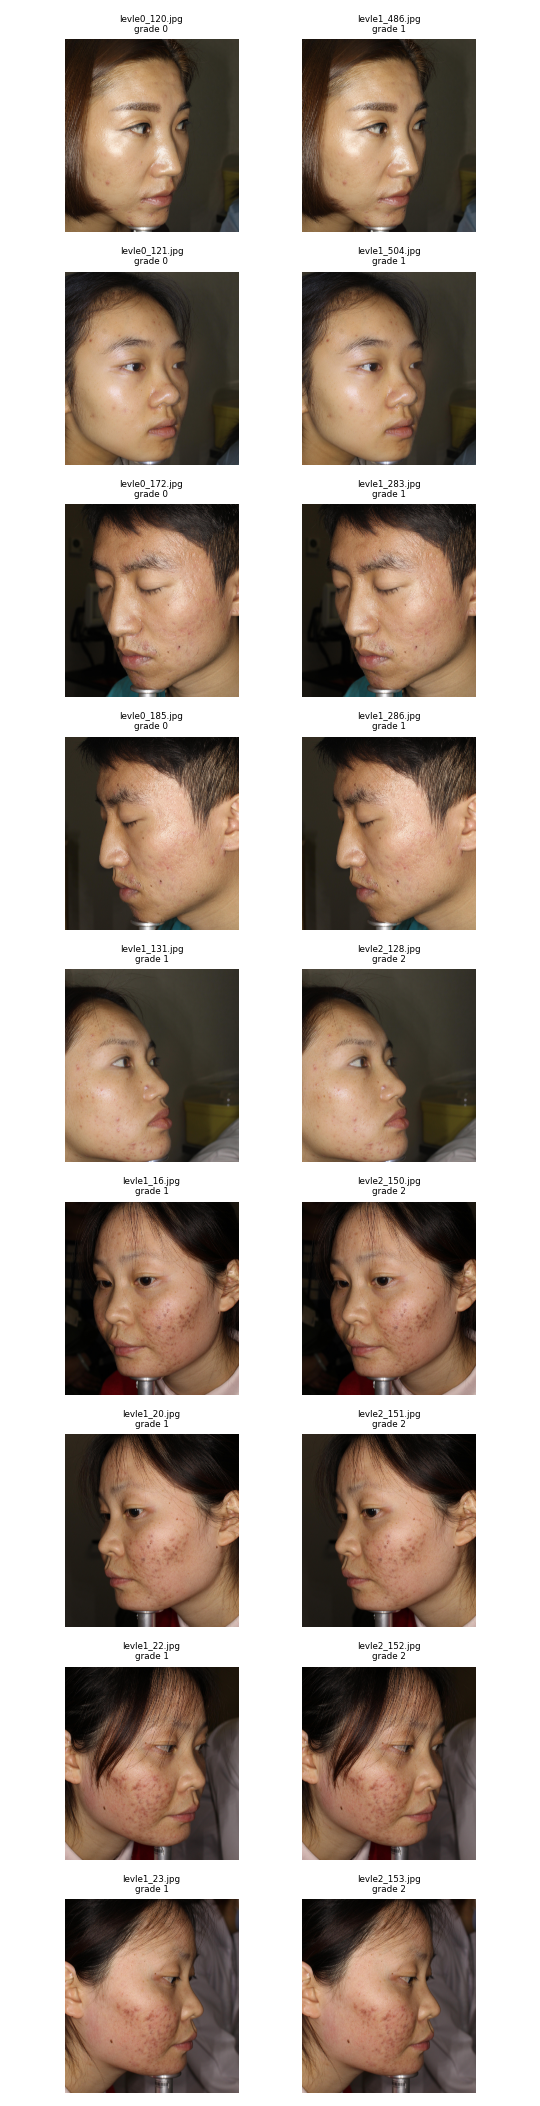

In [4]:
from IPython.display import Image as IPImage, display
from pathlib import Path

p = Path(OUT) / "cross_grade_duplicates.png"
if p.exists():
    display(IPImage(filename=str(p)))
else:
    print("no cross_grade_duplicates.png - no cross-grade duplicates were confirmed")